<a href="https://colab.research.google.com/github/LalTamatar/Neural-link/blob/main/flower_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2 #pil and cv2 are used to process the image
import os #open the file path of the image
import PIL
import tensorflow as tf

from tensorflow import keras
from keras import layers
from keras.models import Sequential

In [ ]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flowert_photos', origin=dataset_url, cache_dir='.', untar=True )

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
data_dir

'./datasets/flowert_photos'

In [ ]:
import pathlib #to create and handle file
data_dir = pathlib.Path(data_dir)
data_dir

PosixPath('datasets/flowert_photos')

In [ ]:
list(data_dir.glob('*/*.jpg')) #here the problem is it only checks upto 2 level down

[]

In [ ]:
print(data_dir.resolve())
print(data_dir.exists())  # Should return True


/content/datasets/flowert_photos
True


In [ ]:
# Print everything inside data_dir to see how it's spelled and structured
print([p.name for p in data_dir.iterdir()])


['flower_photos']


In [ ]:
len(list(data_dir.rglob('*.jpg'))) #use to find the path recursively

3670

In [ ]:
roses = list(data_dir.rglob('roses/*'))
roses[:5]

[PosixPath('datasets/flowert_photos/flower_photos/roses/4713533500_fcc295de70_n.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/roses/14145188939_b4de638bd3_n.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/roses/3264570182_c7ded528ba_m.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/roses/9609569441_eeb8566e94.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/roses/12406418663_af20dc225f_n.jpg')]

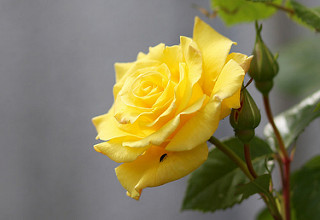

In [ ]:
PIL.Image.open(str(roses[1]))

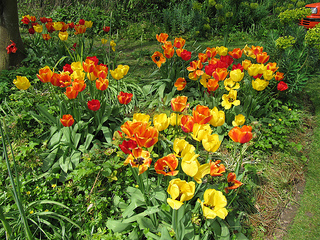

In [ ]:
tulips = list(data_dir.rglob('tulips/*'))
PIL.Image.open(str(tulips[0]))

In [ ]:
flowers_image_dict = {
    'roses': list(data_dir.rglob('roses/*')),
    'daisy': list(data_dir.rglob('daisy/*')),
    'dandelion': list(data_dir.rglob('dandelion/*')),
    'sunflowers': list(data_dir.rglob('sunflowers/*')),
    'tulips': list(data_dir.rglob('tulips/*'))
}

In [ ]:
flowers_image_dict['daisy']

[PosixPath('datasets/flowert_photos/flower_photos/daisy/2539552964_921cf645ba_n.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/daisy/799952628_bf836677fa_n.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/daisy/12701063955_4840594ea6_n.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/daisy/10841136265_af473efc60.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/daisy/7669550908_bc5a11276f_n.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/daisy/3494265422_9dba8f2191_n.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/daisy/294451721_5106537b34.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/daisy/2632216904_274aa17433.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/daisy/5765646947_82e95a9cc9_n.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/daisy/4144275653_7c02d47d9b.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/daisy/8710109684_e2c5ef6aeb_n.jpg'),
 PosixPath('datasets/flowert_photos/flower_photos/d

In [ ]:
flowers_labels_dict ={
    'roses': 0,
    'daisy':1,
    'dandelion':2,
    'sunflowers':3,
    'tulips':4
}

In [ ]:
img = cv2.imread(flowers_image_dict['roses'][0])
img.shape

(240, 320, 3)

In [ ]:
cv2.resize(img,(180, 180)).shape #resizing the image so it will be easier for the model to train as there are images of different pixel size

(180, 180, 3)

In [ ]:
X, y = [], []

for flower_name, images in flowers_image_dict.items():
  for image in images:
    img = cv2.imread(str(image))
    resized_img = cv2.resize(img, (180, 180))
    X.append(resized_img)
    y.append(flowers_labels_dict[flower_name])

    #so basically what we are doing here is we created two list namely X and y
    #in X we will store the resized image and in y, we will store its correspomding value
    #so we iterate through the dictionary using the for loop syntax
    #we provided the variable img with the neccessary info the image in 3d array
    #then we resized the image and sotred it into resized_img
    #the resized img is then appended into X and its corresponding class is stored in y

In [ ]:
y[:5]

[0, 0, 0, 0, 0]

In [ ]:
X=np.array(X)
y=np.array(y)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, y, random_state=0)

here we used the another sklearn tool that's called train_test_split. What it does is, it will split the X and y that we have into 4 categories as given above at random. The default split is 75:25. and the random state ensures that the shuffle=0 remains the same everytime i run it again. Basically, for this model, we don't have predefined Xtrain or Xtest, so we have to make it ourselves


In [ ]:
len(X_train)

2752

In [ ]:
len(X_test)

918

In [ ]:
X_train_scaled = X_train/255
X_test_scaled = X_test/255 #basically scaling like we always do


In [ ]:
X_train_scaled[0]

array([[[0.0627451 , 0.1372549 , 0.1254902 ],
        [0.0745098 , 0.15294118, 0.14117647],
        [0.07843137, 0.16470588, 0.14509804],
        ...,
        [0.14117647, 0.16862745, 0.16862745],
        [0.12941176, 0.15686275, 0.15294118],
        [0.11372549, 0.1372549 , 0.13333333]],

       [[0.07058824, 0.14509804, 0.12941176],
        [0.0745098 , 0.15686275, 0.14509804],
        [0.08235294, 0.17647059, 0.15686275],
        ...,
        [0.1372549 , 0.16862745, 0.16862745],
        [0.12156863, 0.14901961, 0.14901961],
        [0.10980392, 0.13333333, 0.12941176]],

       [[0.05882353, 0.14509804, 0.1254902 ],
        [0.07843137, 0.16470588, 0.14901961],
        [0.07843137, 0.18039216, 0.15686275],
        ...,
        [0.1372549 , 0.16470588, 0.17647059],
        [0.11764706, 0.14901961, 0.14509804],
        [0.10980392, 0.13333333, 0.12941176]],

       ...,

       [[0.        , 0.10588235, 0.0627451 ],
        [0.00784314, 0.05098039, 0.00392157],
        [0.        , 0

In [ ]:
model = Sequential([
    layers.Conv2D(16, 3, padding='same', activation='relu'), #16 is basically the number of subparts and size is 3x3
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    #dense network
    #first flattening the values
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(flowers_labels_dict))
])

model.compile(optimizer='adam',
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits= True),
              metrics=['accuracy'])



In [ ]:
from keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience =8,
    restore_best_weights=True,
    verbose =1 #bascially to print the message if the epochs are done
)
model.fit(X_train_scaled, Y_train, epochs = 100, batch_size = 256, validation_data=(X_test_scaled, Y_test), callbacks=[early_stopping])

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 669ms/step - accuracy: 0.4153 - loss: 1.3754 - val_accuracy: 0.4270 - val_loss: 1.2491
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 201ms/step - accuracy: 0.4524 - loss: 1.2217 - val_accuracy: 0.5011 - val_loss: 1.1360
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 199ms/step - accuracy: 0.5207 - loss: 1.1062 - val_accuracy: 0.5490 - val_loss: 1.0727
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 202ms/step - accuracy: 0.5839 - loss: 1.0203 - val_accuracy: 0.5730 - val_loss: 1.0135
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 202ms/step - accuracy: 0.6177 - loss: 0.9609 - val_accuracy: 0.5839 - val_loss: 0.9999
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 243ms/step - accuracy: 0.6355 - loss: 0.9129 - val_accuracy: 0.6057 - val_loss: 1.0238
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 203ms/step - accuracy: 0.6711 - loss: 0.8565 - val_accuracy: 0.6242 - val_loss: 0.9670
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 204ms/step - accuracy: 0.6944 - loss: 0.7927 - val_accu

In [ ]:
model.evaluate(X_test_scaled, Y_test)

29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.6634 - loss: 0.9177


[0.9176936149597168, 0.6633986830711365]

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.3)
]) #can be used to make more sample

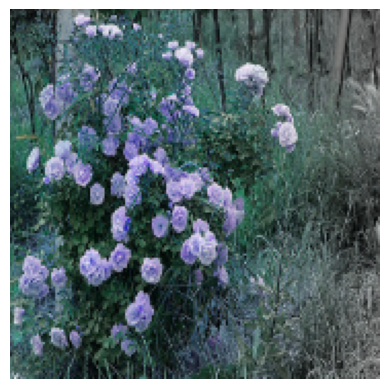

In [ ]:
plt.axis('off')
plt.imshow(X[0])

In [ ]:
data_augmentation(X)[0]

<tf.Tensor: shape=(180, 180, 3), dtype=float32, numpy=
array([[[ 46.565933,  85.29431 ,  87.23289 ],
        [ 40.68769 ,  70.64137 ,  68.10116 ],
        [ 27.279606,  37.567917,  40.02211 ],
        ...,
        [ 24.168087,  24.987762,  24.987762],
        [ 98.80856 ,  98.91623 ,  98.7009  ],
        [119.961266, 120.63769 , 118.85656 ]],

       [[ 54.639893,  87.08026 ,  88.869705],
        [ 47.22311 ,  62.6802  ,  63.526154],
        [ 14.030895,  23.77857 ,  24.089369],
        ...,
        [ 28.277102,  28.58958 ,  28.58958 ],
        [107.61943 , 106.93085 , 106.71551 ],
        [120.574326, 121.53948 , 119.574326]],

       [[ 33.86582 ,  47.609364,  44.89475 ],
        [ 19.162123,  33.760437,  32.43686 ],
        [ 55.935314,  78.35688 ,  75.04389 ],
        ...,
        [ 47.038925,  47.158875,  47.158875],
        [110.49681 , 109.712135, 109.4968  ],
        [122.043945, 123.043945, 121.043945]],

       ...,

       [[ 38.717243,  63.073257,  54.064335],
        [ 31.

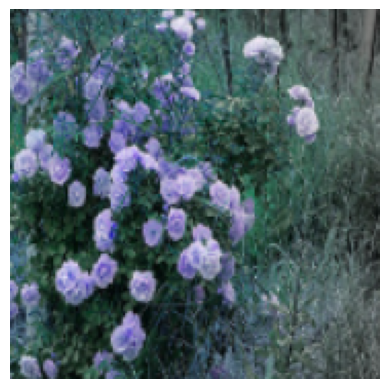

In [ ]:
plt.axis('off')
plt.imshow(data_augmentation(X)[0].numpy().astype("uint8"))

In [ ]:
model = Sequential([
    data_augmentation,
    layers.Conv2D(16, 3, padding='same', activation='relu'), #16 is basically the number of subparts and size is 3x3
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Dropout(0.2), #randomly disables the neuron

    #dense network
    #first flattening the values
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(flowers_labels_dict))
])

model.compile(optimizer='adam',
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits= True),
              metrics=['accuracy'])

early = EarlyStopping(
    monitor='val_loss',
    patience =8,
    restore_best_weights=True,
    verbose =1 #bascially to print the message if the epochs are done
)
model.fit(X_train_scaled, Y_train, epochs = 100, batch_size = 256, validation_data=(X_test_scaled, Y_test), callbacks=[early])


Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 16s 702ms/step - accuracy: 0.2140 - loss: 1.7928 - val_accuracy: 0.2723 - val_loss: 1.5316
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 239ms/step - accuracy: 0.3634 - loss: 1.4411 - val_accuracy: 0.3834 - val_loss: 1.3527
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 252ms/step - accuracy: 0.4691 - loss: 1.2484 - val_accuracy: 0.5011 - val_loss: 1.1844
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 242ms/step - accuracy: 0.5211 - loss: 1.1420 - val_accuracy: 0.5523 - val_loss: 1.0941
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 240ms/step - accuracy: 0.5672 - loss: 1.0801 - val_accuracy: 0.5991 - val_loss: 1.0629
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step - accuracy: 0.5810 - loss: 1.0385 - val_accuracy: 0.5817 - val_loss: 1.0425
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 242ms/step - accuracy: 0.5930 - loss: 1.0242 - val_accuracy: 0.6318 - val_loss: 0.9937
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 243ms/step - accuracy: 0.6177 - loss: 0.9713 - val_acc

In [ ]:
model.evaluate(X_test_scaled, Y_test)

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7342 - loss: 0.7171


[0.7170835733413696, 0.7342047691345215]